# Task 2 — Image-to-Image Generation with Stable Diffusion

**Assignment 6 · Image Generation by Stable Diffusion.** This notebook implements **Task 2**:
take a real input image plus a text prompt and generate a *modified* version of that image,
then study the central knob — **denoising strength** — and the preservation-vs-prompt
trade-off it controls.

| Report section | Where it is produced |
|---|---|
| §2 SD architecture / img2img mechanism | §2 |
| §3 Dataset (≥10 input images) | §3 |
| §6 Experimental setup | §4–§5 |
| §7 Results | §5–§6 (input→output grids, multiple outputs) |
| §10 Parameter analysis | §7 (strength, guidance, steps, prompt) |
| §8 Quantitative evaluation | §8 (CLIP-text, CLIP-image, SSIM, FID) |
| §12 Discussion (preserve vs follow prompt) | §9 trade-off curve + §10 |

### The "Important Question": what are `x` and `y` for image-to-image?

- **`x` (condition) = an input image *and* a text prompt.**
- **`y` (target) = the edited image** that keeps the input's structure but follows the prompt.

Unlike text-to-image (Task 1, conditioned on text alone), img2img conditions on **pixels as
well as text**. Crucially, this is achieved **without training a new model or adding UNet
input channels**: the pretrained text-to-image UNet is reused, and the input image enters
through *initialization* — it is VAE-encoded to a latent, partially noised to a level set by
`strength`, and then denoised under the prompt. So `strength` literally sets how much of the
input is destroyed before regeneration: `strength=0` returns the input, `strength=1` ignores
it (pure text-to-image). That is the difference from inpainting/outpainting, which add an
explicit image latent **and a mask** to a 9-channel UNet.

## 0. Environment

Same stack as Task 1 (skip if already installed).

In [1]:
%pip install -q "diffusers>=0.27" "transformers>=4.38" accelerate peft datasets safetensors ftfy "torchmetrics[image]" scipy matplotlib pandas pillow tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Imports and configuration

Img2img is an **inference-time** technique, so there is no training loop here — the model is
the frozen pretrained Stable Diffusion. Optionally we can load the **Task-1 LoRA** to apply
the fine-tuned style during editing (`use_finetuned_lora`).

In [2]:
import os, gc, json, math, random
from pathlib import Path
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm

import torch
from torchvision import transforms  # noqa (kept for parity / optional use)

torch.backends.cuda.matmul.allow_tf32 = True

@dataclass
class CFG:
    model_id: str = "stable-diffusion-v1-5/stable-diffusion-v1-5"
    resolution: int = 512

    # input images (real photos + captions); tried in order, first that loads wins
    img_dataset_candidates: tuple = (
        "sayakpaul/coco-30-val-2014",   # cols [image, caption] — real COCO photos
        "zh-plus/tiny-imagenet",        # cols [image, label]
        "nielsr/CelebA-faces",          # cols [image]
    )
    use_local_images: bool = True       # use the assignment's "test images" folder
    local_images_dir: str = "test images"
    n_inputs: int = 10                  # assignment requires >= 10

    # optional: reuse the Task-1 fine-tuned LoRA style
    use_finetuned_lora: bool = False
    ft_lora_dir: str = "outputs/lora"

    # generation defaults
    strength: float = 0.6               # denoising strength (0=keep input, 1=ignore input)
    guidance_scale: float = 7.5
    num_inference_steps: int = 40       # keep high so strength*steps >= 1 for small strengths
    seed: int = 42

    n_fid_images: int = 10
    quick_mode: bool = True

CFG = CFG()
if CFG.quick_mode:
    CFG.n_fid_images = 10

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(CFG.seed)

device = "cuda" if torch.cuda.is_available() else "cpu"
use_cuda = device == "cuda"
if use_cuda and torch.cuda.is_bf16_supported():
    weight_dtype = torch.bfloat16
elif use_cuda:
    weight_dtype = torch.float16
else:
    weight_dtype = torch.float32

OUT = Path("outputs_task2")
FIG, RES_DIR, GEN = OUT/"figures", OUT/"results", OUT/"generated"
for d in (FIG, RES_DIR, GEN): d.mkdir(parents=True, exist_ok=True)

print(f"device={device}  gpu={torch.cuda.get_device_name(0) if use_cuda else 'cpu'}  dtype={weight_dtype}")
print("config:", json.dumps(asdict(CFG), indent=2))

device=cuda  gpu=NVIDIA GeForce RTX 5070 Ti  dtype=torch.bfloat16
config: {
  "model_id": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "resolution": 512,
  "img_dataset_candidates": [
    "sayakpaul/coco-30-val-2014",
    "zh-plus/tiny-imagenet",
    "nielsr/CelebA-faces"
  ],
  "use_local_images": true,
  "local_images_dir": "test images",
  "n_inputs": 10,
  "use_finetuned_lora": false,
  "ft_lora_dir": "outputs/lora",
  "strength": 0.6,
  "guidance_scale": 7.5,
  "num_inference_steps": 40,
  "seed": 42,
  "n_fid_images": 10,
  "quick_mode": true
}


## 2. Model and the img2img pipeline (report §2)

We load `StableDiffusionImg2ImgPipeline` — the same VAE + CLIP text encoder + UNet as Task 1,
wired for the img2img sampling schedule. All components are **frozen** (no training). We use a
fast DPM-Solver scheduler. If `use_finetuned_lora` is on and the Task-1 adapter exists, it is
loaded so edits carry the fine-tuned style.

In [3]:
from diffusers import StableDiffusionImg2ImgPipeline, DPMSolverMultistepScheduler

pipe = StableDiffusionImg2ImgPipeline.from_pretrained(
    CFG.model_id, torch_dtype=weight_dtype, safety_checker=None, requires_safety_checker=False)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)
pipe = pipe.to(device)

if CFG.use_finetuned_lora and Path(CFG.ft_lora_dir).exists():
    pipe.load_lora_weights(CFG.ft_lora_dir)
    print(f"loaded fine-tuned LoRA from {CFG.ft_lora_dir}")
else:
    print("using base (un-fine-tuned) Stable Diffusion")

def count_params(m): return sum(p.numel() for p in m.parameters())
arch = pd.DataFrame([
    {"Component": "Text encoder (CLIP ViT-L/14)", "Params (M)": round(count_params(pipe.text_encoder)/1e6, 2)},
    {"Component": "VAE (AutoencoderKL)",          "Params (M)": round(count_params(pipe.vae)/1e6, 2)},
    {"Component": "UNet (denoiser)",              "Params (M)": round(count_params(pipe.unet)/1e6, 2)},
])
arch.loc[len(arch)] = ["TOTAL", round(arch["Params (M)"].sum(), 2)]
arch.to_csv(RES_DIR/"architecture.csv", index=False)
print(f"model {CFG.model_id} @ {CFG.resolution}px, scheduler = {pipe.scheduler.__class__.__name__}")
arch

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

using base (un-fine-tuned) Stable Diffusion
model stable-diffusion-v1-5/stable-diffusion-v1-5 @ 512px, scheduler = DPMSolverMultistepScheduler


,Component,Params (M)
0,Text encoder (CLIP ViT-L/14),123.06
1,VAE (AutoencoderKL),83.65
2,UNet (denoiser),859.52
3,TOTAL,1066.23


## 3. Input images (report §3)

At least 10 real photos. We use COCO validation images (real, varied scenes) and centre-crop
each to a square `resolution`. To use your own / the class images instead, set
`CFG.use_local_images = True` and drop images into `CFG.local_images_dir`.

Loaded 10 LOCAL images from test images


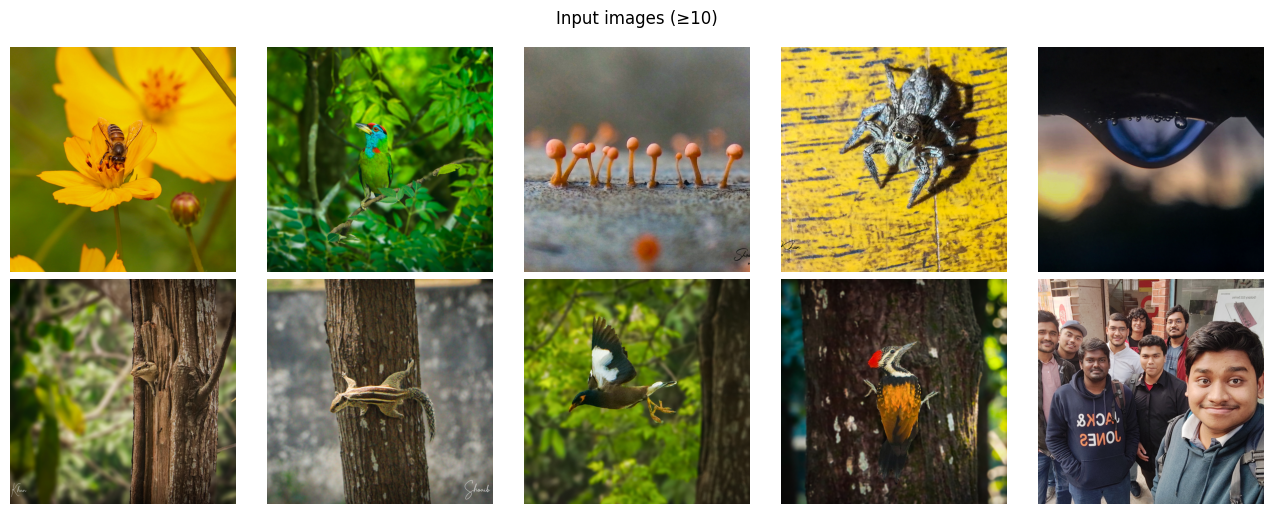

In [4]:
from datasets import load_dataset
from datasets.features import Image as HFImage

def prep_image(img):
    return ImageOps.fit(img.convert("RGB"), (CFG.resolution, CFG.resolution), Image.LANCZOS)

inputs = []   # list of dicts: {image, caption}
if CFG.use_local_images and Path(CFG.local_images_dir).exists():
    paths = sorted([p for p in Path(CFG.local_images_dir).iterdir()
                    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}])
    for p in paths[:CFG.n_inputs]:
        inputs.append({"image": prep_image(Image.open(p)), "caption": p.stem.replace("_", " ")})
    print(f"Loaded {len(inputs)} LOCAL images from {CFG.local_images_dir}")
else:
    ds = None
    for name in CFG.img_dataset_candidates:
        try:
            ds = load_dataset(name, split="train", streaming=True)
            src = name; break
        except Exception as e:
            print(f"[skip] {name}: {type(e).__name__}: {str(e).splitlines()[0][:70]}")
    assert ds is not None, "no candidate image dataset could be loaded; set use_local_images=True"
    feats = ds.features
    img_col = next((c for c, f in feats.items() if isinstance(f, HFImage)), "image")
    cap_col = next((c for c in ["caption", "text", "name"] if c in feats), None)
    for ex in ds:
        cap = ex.get(cap_col) if cap_col else None
        inputs.append({"image": prep_image(ex[img_col]),
                       "caption": cap if isinstance(cap, str) else "a photo"})
        if len(inputs) >= CFG.n_inputs: break
    print(f"Loaded {len(inputs)} images from {src}")

def grid(images, titles=None, ncols=5, figsize_scale=2.6, suptitle=None, fname=None):
    n = len(images); ncols = min(ncols, n); nrows = math.ceil(n/ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_scale*ncols, figsize_scale*nrows))
    axes = np.array(axes).reshape(-1)
    for i, ax in enumerate(axes):
        if i < n:
            ax.imshow(images[i]); ax.axis("off")
            if titles: ax.set_title(titles[i], fontsize=8)
        else: ax.axis("off")
    if suptitle: fig.suptitle(suptitle)
    fig.tight_layout()
    if fname: fig.savefig(FIG/fname, dpi=130, bbox_inches="tight")
    plt.show()

grid([d["image"] for d in inputs], ncols=5, suptitle="Input images (≥10)",
     fname="t2_input_images.png")

## 4. Edit prompts (report §6)

Each input image is paired with a distinct **edit prompt** describing the desired
transformation (style or scene). Using style prompts that apply to *any* photo keeps the
comparison fair across the ten different inputs and makes prompt-adherence measurable with
CLIP.

In [5]:
STYLE_PROMPTS = [
    "a watercolor painting",
    "an oil painting in the style of Van Gogh, thick brush strokes",
    "a detailed pencil sketch, black and white",
    "a vibrant pop-art illustration",
    "a cyberpunk scene with neon lights at night",
    "a snowy winter scene, covered in snow",
    "warm golden-hour sunset lighting, autumn colors",
    "a futuristic sci-fi concept art, cinematic",
    "a Studio Ghibli style anime illustration",
    "a vintage sepia-toned photograph with film grain",
]
for i, d in enumerate(inputs):
    d["prompt"] = STYLE_PROMPTS[i % len(STYLE_PROMPTS)]
print(f"{len(inputs)} (image, prompt) pairs")
for d in inputs[:3]:
    print(" -", d["prompt"])

10 (image, prompt) pairs
 - a watercolor painting
 - an oil painting in the style of Van Gogh, thick brush strokes
 - a detailed pencil sketch, black and white


## 5. Generate modified versions (report §7)

The core img2img call. For each of the ≥10 (image, prompt) pairs we generate one edited
image at the default strength and show input → output side by side.

img2img:   0%|          | 0/10 [00:00<?, ?it/s]

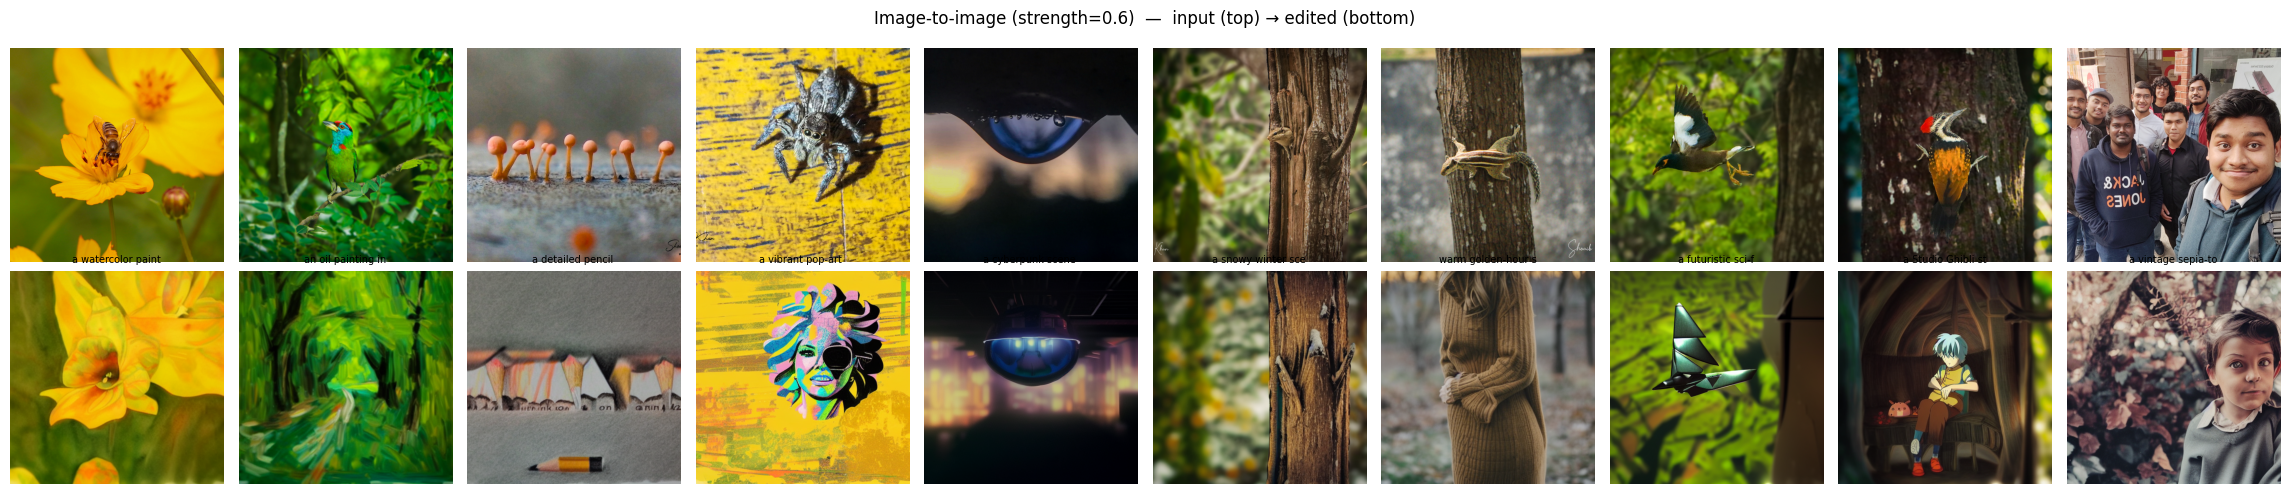

In [6]:
def img2img(image, prompt, strength=None, guidance=None, steps=None, seed=0, negative_prompt=None):
    g = torch.Generator(device=device).manual_seed(seed)
    out = pipe(prompt=prompt, image=image,
               strength=strength if strength is not None else CFG.strength,
               guidance_scale=guidance if guidance is not None else CFG.guidance_scale,
               num_inference_steps=steps or CFG.num_inference_steps,
               negative_prompt=negative_prompt, generator=g)
    return out.images[0]

outputs = [img2img(d["image"], d["prompt"], seed=CFG.seed)
           for d in tqdm(inputs, desc="img2img")]
for i, im in enumerate(outputs):
    im.save(GEN/f"edit_{i:02d}.png")

# input (top) vs output (bottom) grid
n = len(inputs)
fig, axes = plt.subplots(2, n, figsize=(2.3*n, 5.0))
for i in range(n):
    axes[0, i].imshow(inputs[i]["image"]); axes[0, i].axis("off")
    axes[1, i].imshow(outputs[i]);         axes[1, i].axis("off")
    axes[1, i].set_title(inputs[i]["prompt"][:18], fontsize=7)
axes[0, 0].set_ylabel("input", fontsize=10); axes[1, 0].set_ylabel("output", fontsize=10)
fig.suptitle(f"Image-to-image (strength={CFG.strength})  —  input (top) → edited (bottom)")
fig.tight_layout(); fig.savefig(FIG/"t2_input_output.png", dpi=130, bbox_inches="tight"); plt.show()

## 6. Multiple outputs per image (report §7)

For selected inputs, several random seeds at fixed prompt/strength show the diversity of
edits the model produces from the same starting image.

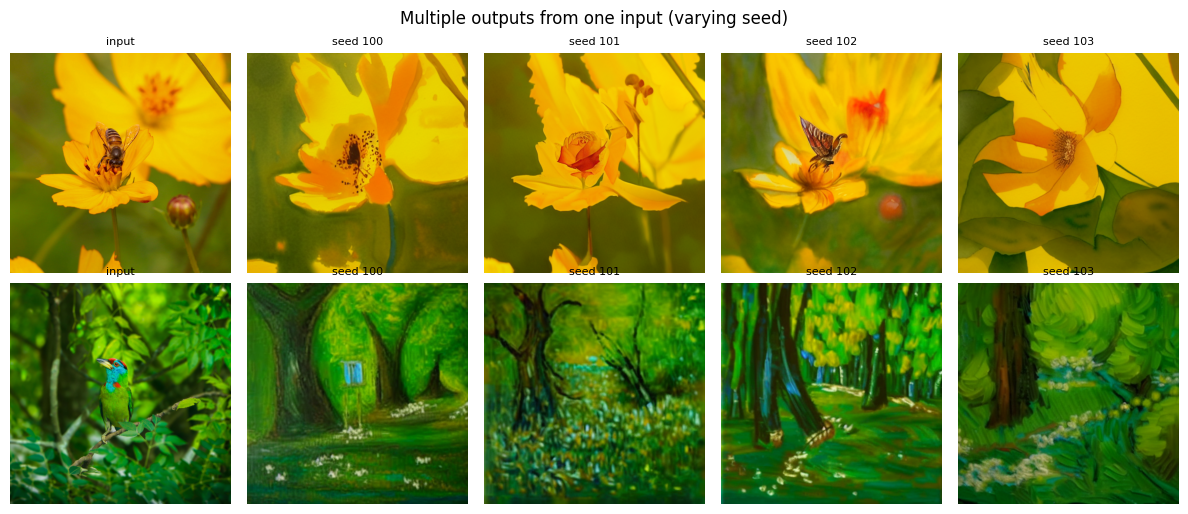

In [7]:
sel = list(range(min(2, len(inputs))))
n_variants = 4
fig, axes = plt.subplots(len(sel), n_variants + 1, figsize=(2.4*(n_variants+1), 2.6*len(sel)))
axes = np.array(axes).reshape(len(sel), n_variants + 1)
for r, idx in enumerate(sel):
    axes[r, 0].imshow(inputs[idx]["image"]); axes[r, 0].axis("off")
    axes[r, 0].set_title("input", fontsize=8)
    for c in range(n_variants):
        im = img2img(inputs[idx]["image"], inputs[idx]["prompt"], seed=100 + c)
        axes[r, c+1].imshow(im); axes[r, c+1].axis("off")
        axes[r, c+1].set_title(f"seed {100+c}", fontsize=8)
fig.suptitle("Multiple outputs from one input (varying seed)")
fig.tight_layout(); fig.savefig(FIG/"t2_multiple_outputs.png", dpi=130, bbox_inches="tight"); plt.show()

## 7. Parameter experiments (report §10)

Vary one parameter at a time on a fixed (image, prompt): **denoising strength**, guidance
scale, inference steps, and the prompt itself.

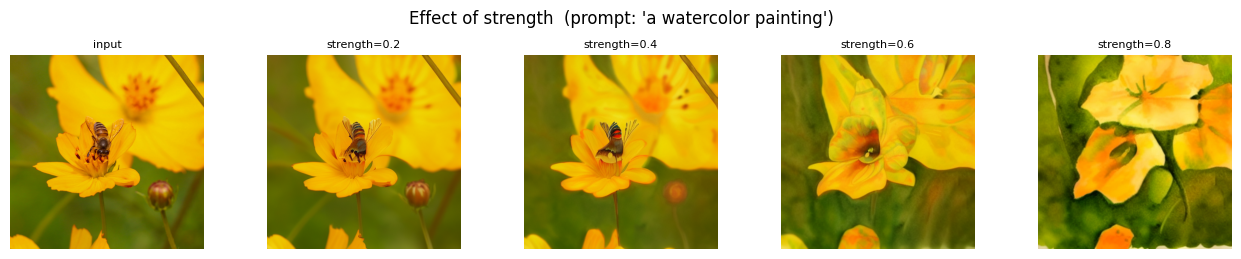

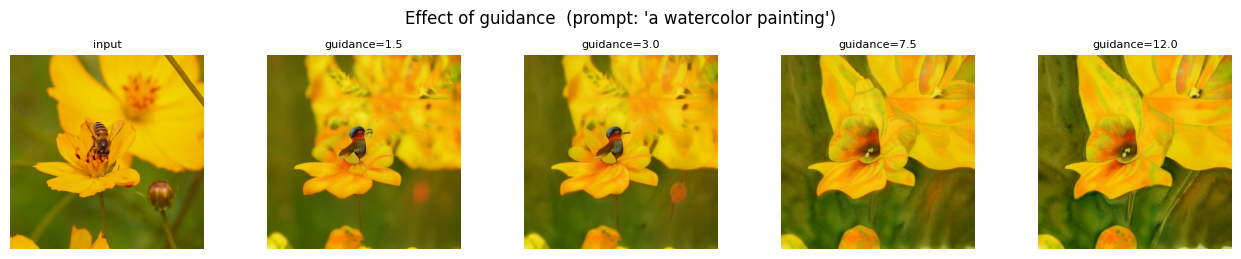

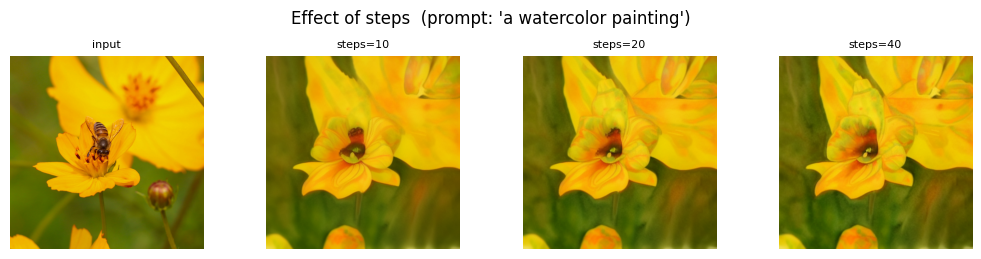

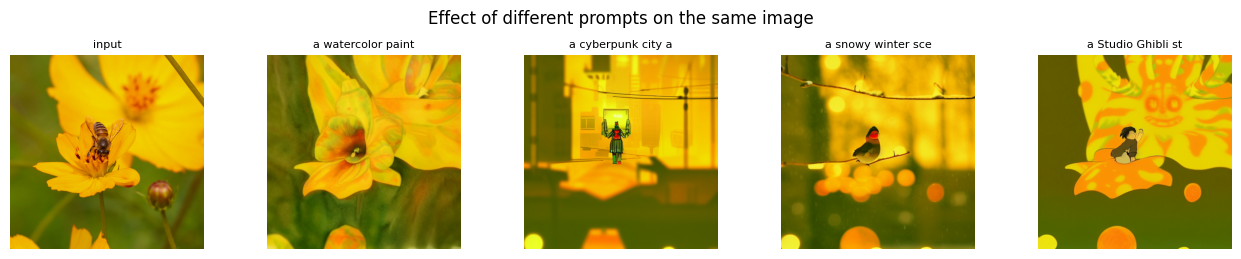

In [8]:
base = inputs[0]
img0, prm0 = base["image"], base["prompt"]

def sweep_grid(param, values):
    imgs, labels = [img0], ["input"]
    for v in values:
        kw = dict(strength=CFG.strength, guidance=CFG.guidance_scale, steps=CFG.num_inference_steps, seed=CFG.seed)
        kw[param] = v
        imgs.append(img2img(img0, prm0, **kw)); labels.append(f"{param}={v}")
    grid(imgs, titles=labels, ncols=len(imgs), figsize_scale=2.6,
         suptitle=f"Effect of {param}  (prompt: '{prm0}')", fname=f"t2_sweep_{param}.png")

sweep_grid("strength", [0.2, 0.4, 0.6, 0.8])
sweep_grid("guidance", [1.5, 3.0, 7.5, 12.0])
sweep_grid("steps",    [10, 20, 40])

# different prompts on the SAME input image
prompt_variants = ["a watercolor painting", "a cyberpunk city at night",
                   "a snowy winter scene", "a Studio Ghibli style anime illustration"]
imgs, labels = [img0], ["input"]
for p in prompt_variants:
    imgs.append(img2img(img0, p, seed=CFG.seed)); labels.append(p[:18])
grid(imgs, titles=labels, ncols=len(imgs), figsize_scale=2.6,
     suptitle="Effect of different prompts on the same image", fname="t2_sweep_prompt.png")

## 8. Quantitative evaluation (report §8)

For every edited image we measure:

- **CLIP-text** — cosine(prompt, output) ×100: does the output follow the prompt?
- **CLIP-image** — cosine(input, output): how much of the input is preserved (semantic)?
- **SSIM** — structural similarity to the input: pixel-level preservation.
- **FID** — output distribution vs the input photos; indicative only at this sample size.

In [9]:
from torchmetrics.multimodal.clip_score import CLIPScore
from torchmetrics.functional import structural_similarity_index_measure as ssim_fn
from torchmetrics.image.fid import FrechetInceptionDistance

def pil_to_uint8(img): return torch.from_numpy(np.array(img.convert("RGB"))).permute(2,0,1).contiguous()
def pil_to_float(img): return pil_to_uint8(img).float()/255.0

clip_metric = CLIPScore(model_name_or_path="openai/clip-vit-base-patch32").to(device)

@torch.no_grad()
def clip_text_image(img, prompt):
    return float(clip_metric(pil_to_uint8(img).to(device), prompt).cpu())

@torch.no_grad()
def clip_image_image(a, b):
    m, proc = clip_metric.model, clip_metric.processor
    inp = proc(images=[np.array(a.convert("RGB")), np.array(b.convert("RGB"))], return_tensors="pt").to(device)
    f = m.get_image_features(**inp); f = f / f.norm(dim=-1, keepdim=True)
    return float((f[0] @ f[1]).cpu())

rows = []
for i, (d, out) in enumerate(zip(inputs, outputs)):
    a = pil_to_float(out).unsqueeze(0); b = pil_to_float(d["image"]).unsqueeze(0)
    rows.append({"idx": i, "prompt": d["prompt"],
                 "CLIP_text": round(clip_text_image(out, d["prompt"]), 2),
                 "CLIP_img_to_input": round(clip_image_image(out, d["image"]), 3),
                 "SSIM_to_input": round(float(ssim_fn(a, b)), 3)})
metrics_df = pd.DataFrame(rows)
metrics_df.to_csv(RES_DIR/"per_image_metrics.csv", index=False)

# FID: edited outputs vs input photos (cross-distribution — indicative only)
fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
def stack299(imgs): return torch.stack([pil_to_float(im.resize((299,299))) for im in imgs]).to(device)
fid.update(stack299([d["image"] for d in inputs][:CFG.n_fid_images]), real=True)
fid.update(stack299(outputs[:CFG.n_fid_images]), real=False)
fid_val = float(fid.compute().cpu())

summary = {
    "CLIP_text_mean":       round(metrics_df["CLIP_text"].mean(), 2),
    "CLIP_img_to_input_mean": round(metrics_df["CLIP_img_to_input"].mean(), 3),
    "SSIM_to_input_mean":   round(metrics_df["SSIM_to_input"].mean(), 3),
    "FID_out_vs_input":     round(fid_val, 2),
    "strength":             CFG.strength,
    "n_inputs":             len(inputs),
}
json.dump(summary, open(RES_DIR/"summary_metrics.json", "w"), indent=2)
print(json.dumps(summary, indent=2))
metrics_df

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


{
  "CLIP_text_mean": 25.68,
  "CLIP_img_to_input_mean": 0.615,
  "SSIM_to_input_mean": 0.506,
  "FID_out_vs_input": 365.09,
  "strength": 0.6,
  "n_inputs": 10
}


,idx,prompt,CLIP_text,CLIP_img_to_input,SSIM_to_input
0,0,a watercolor painting,26.17,0.809,0.675
1,1,"an oil painting in the style of Van Gogh, thic...",28.93,0.730,0.420
2,2,"a detailed pencil sketch, black and white",23.33,0.685,0.563
3,3,a vibrant pop-art illustration,29.02,0.385,0.275
4,4,a cyberpunk scene with neon lights at night,26.38,0.726,0.759
5,5,"a snowy winter scene, covered in snow",23.45,0.815,0.424
6,6,"warm golden-hour sunset lighting, autumn colors",21.68,0.563,0.516
7,7,"a futuristic sci-fi concept art, cinematic",22.95,0.574,0.589
8,8,a Studio Ghibli style anime illustration,29.37,0.470,0.549
9,9,a vintage sepia-toned photograph with film grain,25.50,0.398,0.294


## 9. The preservation vs prompt-following trade-off (report §12)

This is the headline result the assignment asks us to discuss. Sweeping **denoising strength**
on several images and averaging, we plot two curves against strength:

- **prompt adherence** (CLIP-text) — rises with strength;
- **input preservation** (CLIP-image to input, and SSIM) — falls with strength.

Where they cross is the practical operating range: enough strength to apply the edit, little
enough to keep the subject recognisable.

strength trade-off:   0%|          | 0/6 [00:00<?, ?it/s]

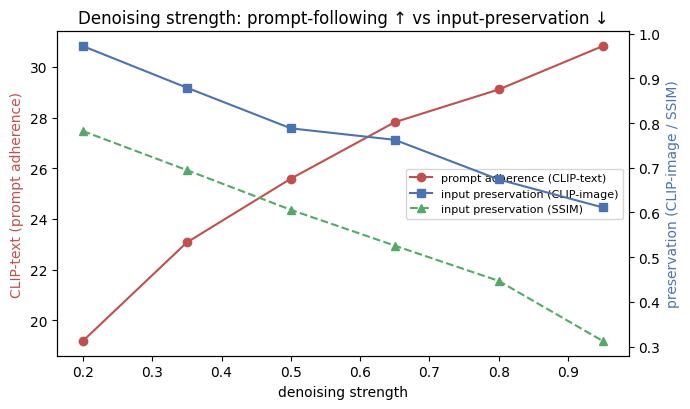

In [10]:
strengths = [0.2, 0.35, 0.5, 0.65, 0.8, 0.95]
n_probe = min(3 if not CFG.quick_mode else 2, len(inputs))
adh, pres_clip, pres_ssim = [], [], []
for s in tqdm(strengths, desc="strength trade-off"):
    a_list, pc_list, ps_list = [], [], []
    for d in inputs[:n_probe]:
        out = img2img(d["image"], d["prompt"], strength=s, seed=CFG.seed)
        a_list.append(clip_text_image(out, d["prompt"]))
        pc_list.append(clip_image_image(out, d["image"]))
        af = pil_to_float(out).unsqueeze(0); bf = pil_to_float(d["image"]).unsqueeze(0)
        ps_list.append(float(ssim_fn(af, bf)))
    adh.append(np.mean(a_list)); pres_clip.append(np.mean(pc_list)); pres_ssim.append(np.mean(ps_list))

pd.DataFrame({"strength": strengths, "CLIP_text": adh,
              "CLIP_img_to_input": pres_clip, "SSIM_to_input": pres_ssim}
             ).to_csv(RES_DIR/"strength_tradeoff.csv", index=False)

fig, ax1 = plt.subplots(figsize=(7, 4.2))
ax1.plot(strengths, adh, "o-", color="#c0504d", label="prompt adherence (CLIP-text)")
ax1.set_xlabel("denoising strength"); ax1.set_ylabel("CLIP-text (prompt adherence)", color="#c0504d")
ax2 = ax1.twinx()
ax2.plot(strengths, pres_clip, "s-", color="#4c72b0", label="input preservation (CLIP-image)")
ax2.plot(strengths, pres_ssim, "^--", color="#55a868", label="input preservation (SSIM)")
ax2.set_ylabel("preservation (CLIP-image / SSIM)", color="#4c72b0")
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [l.get_label() for l in lines], loc="center right", fontsize=8)
plt.title("Denoising strength: prompt-following ↑ vs input-preservation ↓")
fig.tight_layout(); fig.savefig(FIG/"t2_strength_tradeoff.png", dpi=130, bbox_inches="tight"); plt.show()

## 10. Discussion (report §11–§14)

**System.** A Stable-Diffusion-1.5 image-to-image pipeline: the input photo is VAE-encoded,
partially noised to a level set by `strength`, and denoised under a text prompt. All weights
are the frozen pretrained model (optionally the Task-1 LoRA style); **nothing is trained** —
img2img is entirely an inference-time procedure.

**The preservation vs prompt trade-off (the required discussion).** Denoising strength is the
single dominant control. At low strength (≈0.2–0.35) the output is almost the input with a
light restyle — high SSIM/CLIP-image, low prompt adherence. At high strength (≈0.8–0.95) the
prompt dominates and the input is barely recognisable — high CLIP-text, low preservation.
The §9 curves cross in the **≈0.5–0.65** band, which is the usual sweet spot: the edit is
clearly applied while the subject and composition survive.

**Other parameters.** Guidance scale trades prompt-adherence against artefacts (best ≈6–9);
more inference steps mainly sharpen detail with diminishing returns past ≈30; and different
prompts steer the same input into entirely different styles at fixed strength.

**Evaluation notes.** CLIP-text and CLIP-image capture the two ends of the trade-off directly.
SSIM measures pixel-level preservation. FID here compares edited outputs against the input
photos — a cross-distribution comparison by construction (the edits are *meant* to differ),
so it is indicative of how far the edits move, not a quality score, and it is computed on few
images.

**Limitations.** Single seed per point on most grids; a fixed style-prompt set; img2img cannot
add or remove specific objects reliably (that is inpainting's job); very high strength can
drift off the input entirely.

**Bridge to the other tasks (the "Important Question").**

| Task | `x` (condition) | `y` (target) | UNet input |
|---|---|---|---|
| Text-to-image (Task 1) | text | image | 4-ch latent |
| **Image-to-image (this task)** | **text + input image (via noised latent init)** | edited image | 4-ch latent, **no new channels** |
| Inpainting (Task 3) | text + image latent + mask | filled image | 9-ch latent |
| Outpainting (Task 4) | text + image latent + border mask | extended image | 9-ch latent |

Img2img is the key illustration that the *same* text-to-image model can be conditioned on an
image **without any architectural change or training** — purely by where the reverse diffusion
process is started. All figures/tables are saved under `outputs_task2/`.